In [13]:
# ============================================================
# 05_recommendation.ipynb
# Sentiment-Based Hotel Recommendation System (System 2)
#
# Uses DistilBERT confidence scores (prob_positive) produced
# by 05_inference_kaggle.ipynb.
#
# For each hotel: sentiment_score = mean(prob_positive)
# across all its review snippets.
#
# This notebook produces:
#   - The sentiment-based top-10 recommendation
#   - Visualizations related to System 2
#   - results/hotel_scores.csv for the comparison notebook
# ============================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import warnings
warnings.filterwarnings('ignore')

os.makedirs('../results', exist_ok=True)
os.makedirs('../results/visualizations', exist_ok=True)
print('Imports done.')

Imports done.


In [14]:
# ── 1. LOAD DATA ─────────────────────────────────────────────
df = pd.read_csv('../data/processed/hotel_reviews_with_predictions.csv')

required = {'hotel', 'score', 'label', 'distilbert_sentiment',
            'prob_positive', 'prob_negative'}
assert required.issubset(set(df.columns)), \
    f"Missing columns: {required - set(df.columns)}"

print(f"Total review snippets : {len(df):,}")
print(f"Hotels                : {df['hotel'].nunique():,}")
print(f"\nLabel distribution (column-origin):")
print(df['label'].value_counts())
print(f"\nDistilBERT predicted distribution:")
print(df['distilbert_sentiment'].value_counts())
print(f"\nP(Positive) statistics:")
print(df['prob_positive'].describe())

Total review snippets : 709,313
Hotels                : 1,492

Label distribution (column-origin):
label
Positive    399453
Negative    309860
Name: count, dtype: int64

DistilBERT predicted distribution:
distilbert_sentiment
Positive    392885
Negative    316428
Name: count, dtype: int64

P(Positive) statistics:
count    709313.000000
mean          0.551884
std           0.485903
min           0.001142
25%           0.003636
50%           0.979937
75%           0.996519
max           0.998840
Name: prob_positive, dtype: float64


In [15]:
# ── 2. AGGREGATE PER HOTEL ───────────────────────────────────
# sentiment_score = mean P(Positive) across all snippets for that hotel.
# A snippet with prob_positive=0.97 contributes strongly.
# A snippet with prob_positive=0.53 contributes weakly.
# This is richer than counting positive/negative fields.

hotel_stats = df.groupby('hotel').agg(
    n_snippets         = ('prob_positive', 'count'),
    sentiment_score    = ('prob_positive', 'mean'),   # System 2 score
    mean_prob_negative = ('prob_negative', 'mean'),
    n_pred_positive    = ('distilbert_sentiment', lambda x: (x == 'Positive').sum()),
    n_pred_negative    = ('distilbert_sentiment', lambda x: (x == 'Negative').sum()),
    avg_score          = ('score', 'mean'),            # kept for export only
).reset_index()

hotel_stats['pct_pred_positive'] = (
    hotel_stats['n_pred_positive'] / hotel_stats['n_snippets'] * 100
)

# Minimum 50 snippets for a reliable sentiment score
MIN_SNIPPETS = 50
hotel_stats = hotel_stats[
    hotel_stats['n_snippets'] >= MIN_SNIPPETS
].reset_index(drop=True)

print(f"Hotels with ≥{MIN_SNIPPETS} snippets : {len(hotel_stats):,}")
print(f"Sentiment score range : "
      f"{hotel_stats['sentiment_score'].min():.4f} "
      f"to {hotel_stats['sentiment_score'].max():.4f}")
print(f"\nTop 5 by sentiment score:")
print(hotel_stats.nlargest(5, 'sentiment_score')[
    ['hotel', 'n_snippets', 'sentiment_score', 'avg_score']
].to_string(index=False))

Hotels with ≥50 snippets : 1,391
Sentiment score range : 0.3432 to 0.7658

Top 5 by sentiment score:
            hotel  n_snippets  sentiment_score  avg_score
    H tel Moli re         149         0.765799   9.314765
               41         120         0.757157   9.684167
Hotel Casa Camper         377         0.749890   9.657560
     H tel Fabric         130         0.749330   9.460000
     B Montmartre         113         0.749060   9.282301


In [16]:
# ── 3. SENTIMENT-BASED RECOMMENDATION (System 2) ─────────────
def recommend_by_sentiment(top_k=10, min_snippets=50):
    """
    Ranks hotels by mean P(Positive) from the fine-tuned DistilBERT model.

    sentiment_score = average of P(Positive) across all review snippets.
    The score is in [0, 1]:
      → near 1: guests consistently wrote positive things
      → near 0: guests consistently wrote negative things

    Unlike star ratings, this score captures the INTENSITY of sentiment:
    a barely-positive snippet (P=0.53) and a strongly-positive snippet
    (P=0.98) are NOT treated equally.
    """
    candidates = hotel_stats[
        hotel_stats['n_snippets'] >= min_snippets
    ].copy().sort_values('sentiment_score', ascending=False)

    result = candidates.head(top_k)[
        ['hotel', 'n_snippets', 'sentiment_score',
         'mean_prob_negative', 'pct_pred_positive']
    ].reset_index(drop=True)
    result.columns = [
        'Hotel', 'Snippets', 'Sentiment Score',
        'Mean P(Negative)', '% Classified Positive'
    ]
    result.index += 1
    return result

print("=" * 65)
print("SYSTEM 2 — TOP 10 HOTELS  (DistilBERT Sentiment-Based)")
print("=" * 65)
top10 = recommend_by_sentiment(top_k=10, min_snippets=50)
print(top10.to_string())

SYSTEM 2 — TOP 10 HOTELS  (DistilBERT Sentiment-Based)
                                           Hotel  Snippets  Sentiment Score  Mean P(Negative)  % Classified Positive
1                                  H tel Moli re       149         0.765799          0.234201              77.181208
2                                             41       120         0.757157          0.242843              75.833333
3                              Hotel Casa Camper       377         0.749890          0.250110              75.596817
4                                   H tel Fabric       130         0.749330          0.250670              76.153846
5                                   B Montmartre       113         0.749060          0.250940              75.221239
6                                Hotel Le 10 BIS        57         0.747976          0.252024              75.438596
7                        Boutiquehotel Das Tyrol       165         0.741712          0.258288              74.545455
8        

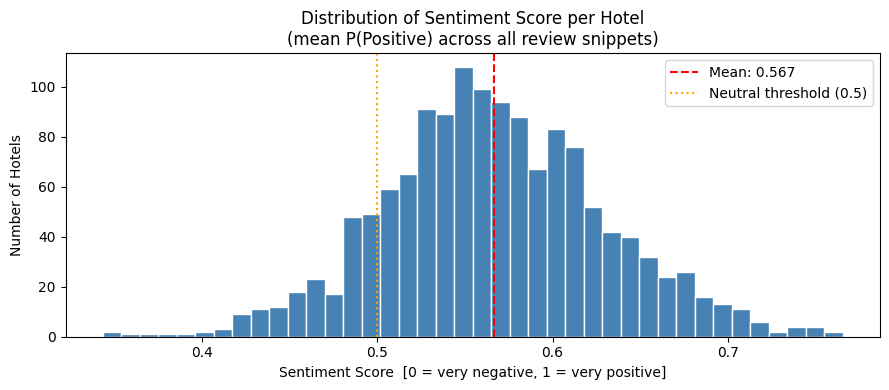

Saved: results/visualizations/sentiment_score_distribution.png


In [17]:
# ── 4. VIZ: SENTIMENT SCORE DISTRIBUTION ─────────────────────
# Shows how mean P(Positive) is distributed across all hotels.
# Most hotels cluster in the upper range — guests tend to write
# positively — but the spread is what differentiates them.

plt.figure(figsize=(9, 4))
plt.hist(hotel_stats['sentiment_score'], bins=40,
         color='steelblue', edgecolor='white')
plt.axvline(hotel_stats['sentiment_score'].mean(), color='red',
            linestyle='--',
            label=f"Mean: {hotel_stats['sentiment_score'].mean():.3f}")
plt.axvline(0.5, color='orange', linestyle=':',
            label='Neutral threshold (0.5)')
plt.title('Distribution of Sentiment Score per Hotel\n'
          '(mean P(Positive) across all review snippets)', fontsize=12)
plt.xlabel('Sentiment Score  [0 = very negative, 1 = very positive]')
plt.ylabel('Number of Hotels')
plt.legend()
plt.tight_layout()
plt.savefig('../results/visualizations/sentiment_score_distribution.png',
            dpi=150)
plt.show()
print('Saved: results/visualizations/sentiment_score_distribution.png')

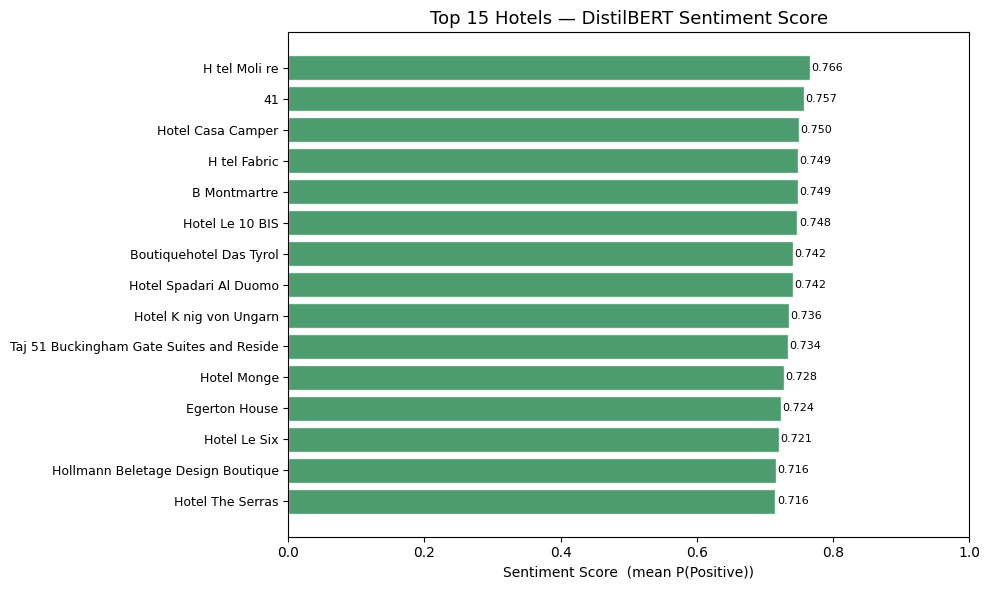

Saved: results/visualizations/top15_sentiment.png


In [18]:
# ── 5. VIZ: TOP 10 BAR CHART ─────────────────────────────────
top15 = hotel_stats.nlargest(15, 'sentiment_score')

plt.figure(figsize=(10, 6))
bars = plt.barh(
    range(len(top15)),
    top15['sentiment_score'],
    color='seagreen', alpha=0.85, edgecolor='white'
)
plt.yticks(range(len(top15)),
           [h[:40] for h in top15['hotel']], fontsize=9)
plt.gca().invert_yaxis()
plt.xlabel('Sentiment Score  (mean P(Positive))')
plt.title('Top 15 Hotels — DistilBERT Sentiment Score', fontsize=13)
for i, score in enumerate(top15['sentiment_score']):
    plt.text(score + 0.002, i, f'{score:.3f}', va='center', fontsize=8)
plt.xlim(0, 1)
plt.tight_layout()
plt.savefig('../results/visualizations/top15_sentiment.png', dpi=150)
plt.show()
print('Saved: results/visualizations/top15_sentiment.png')

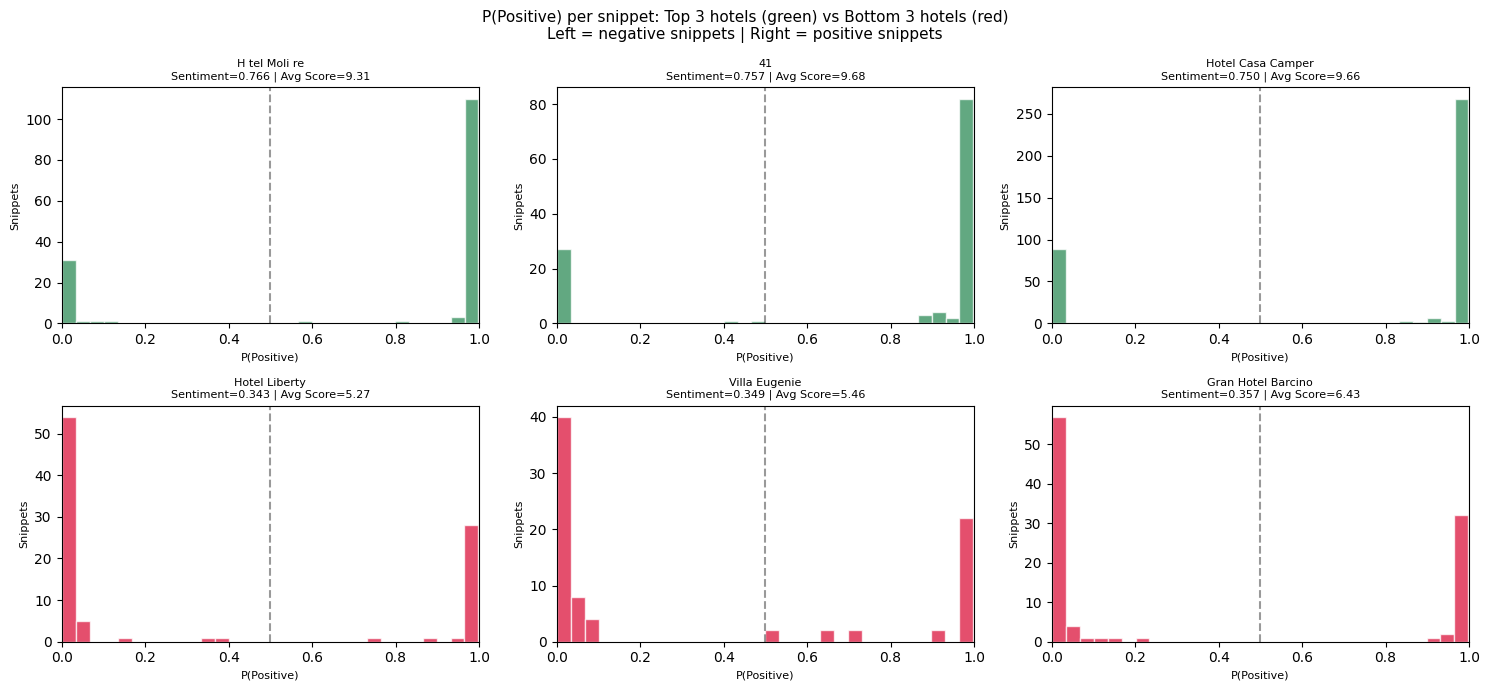

Saved: results/visualizations/confidence_by_hotel.png


In [19]:
# ── 6. VIZ: P(Positive) DISTRIBUTION FOR TOP 3 vs BOTTOM 3 ──
# Shows the snippet-level confidence spread for the best and worst hotels.
# A top hotel should have most snippets clustered near P=1.
# A bottom hotel should have most snippets clustered near P=0.
# This is the clearest visual proof that confidence scores are meaningful.

top3    = hotel_stats.nlargest(3, 'sentiment_score')['hotel'].tolist()
bottom3 = hotel_stats.nsmallest(3, 'sentiment_score')['hotel'].tolist()

fig, axes = plt.subplots(2, 3, figsize=(15, 7))
axes = axes.flatten()

for i, hotel in enumerate(top3 + bottom3):
    hotel_df  = df[df['hotel'] == hotel]
    score_val = hotel_stats.loc[
        hotel_stats['hotel'] == hotel, 'sentiment_score'].values[0]
    avg_s     = hotel_stats.loc[
        hotel_stats['hotel'] == hotel, 'avg_score'].values[0]

    color = 'seagreen' if i < 3 else 'crimson'
    axes[i].hist(hotel_df['prob_positive'], bins=30,
                 color=color, alpha=0.75, edgecolor='white')
    axes[i].axvline(0.5, color='black', linestyle='--', alpha=0.4)
    axes[i].set_title(
        f"{hotel[:35]}\n"
        f"Sentiment={score_val:.3f} | Avg Score={avg_s:.2f}",
        fontsize=8
    )
    axes[i].set_xlabel('P(Positive)', fontsize=8)
    axes[i].set_ylabel('Snippets', fontsize=8)
    axes[i].set_xlim(0, 1)

fig.suptitle(
    'P(Positive) per snippet: Top 3 hotels (green) vs Bottom 3 hotels (red)\n'
    'Left = negative snippets | Right = positive snippets',
    fontsize=11
)
plt.tight_layout()
plt.savefig('../results/visualizations/confidence_by_hotel.png',
            dpi=150, bbox_inches='tight')
plt.show()
print('Saved: results/visualizations/confidence_by_hotel.png')

In [20]:
# ── 7. EXPORT ────────────────────────────────────────────────
# Export hotel_scores.csv for the comparison notebook (07_comparison).
# Contains both the sentiment score (System 2) and avg_score (System 1)
# so your teammate can build the comparison from a single file.

hotel_stats.sort_values('sentiment_score', ascending=False).to_csv(
    '../results/hotel_scores.csv', index=False
)

print('Exported: results/hotel_scores.csv')
print(f'Rows    : {len(hotel_stats):,} hotels')
print(f'Columns : {list(hotel_stats.columns)}')
print()
print('Top 5 by sentiment score:')
print(hotel_stats.nlargest(5, 'sentiment_score')[
    ['hotel', 'n_snippets', 'sentiment_score', 'avg_score']
].to_string(index=False))
print()
print('Bottom 5 by sentiment score:')
print(hotel_stats.nsmallest(5, 'sentiment_score')[
    ['hotel', 'n_snippets', 'sentiment_score', 'avg_score']
].to_string(index=False))

Exported: results/hotel_scores.csv
Rows    : 1,391 hotels
Columns : ['hotel', 'n_snippets', 'sentiment_score', 'mean_prob_negative', 'n_pred_positive', 'n_pred_negative', 'avg_score', 'pct_pred_positive']

Top 5 by sentiment score:
            hotel  n_snippets  sentiment_score  avg_score
    H tel Moli re         149         0.765799   9.314765
               41         120         0.757157   9.684167
Hotel Casa Camper         377         0.749890   9.657560
     H tel Fabric         130         0.749330   9.460000
     B Montmartre         113         0.749060   9.282301

Bottom 5 by sentiment score:
                           hotel  n_snippets  sentiment_score  avg_score
                   Hotel Liberty          93         0.343186   5.269892
                   Villa Eugenie          82         0.348544   5.460976
              Gran Hotel Barcino         100         0.356521   6.426000
         Villa Lut ce Port Royal          64         0.366873   6.212500
Paris Marriott Rive Gauch